# ETF 横截面动量轮动回测

本项目使用沪深300ETF、国债ETF、黄金ETF、纳指ETF和恒生ETF，
构建月频横截面动量轮动策略。

研究重点包括：

- 月频动量信号构造
- 信号与持仓时间对齐
- 前视偏差控制
- 换手率与交易成本
- 基准组合比较
- 样本外测试
- 参数稳健性分析

In [34]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False

print("项目根目录：", project_root)
print("pandas 版本：", pd.__version__)
print("NumPy 版本：", np.__version__)

项目根目录： c:\Users\10529\Documents\quant-projects\etf-momentum-backtest
pandas 版本： 3.0.5
NumPy 版本： 2.4.6


## 1. 数据获取

本项目通过 AkShare 获取东方财富 ETF 日频前复权行情。

完整的数据获取逻辑封装在 `src/data.py` 中，包括：

- AkShare 行情请求
- 请求频率控制
- 本地数据缓存
- 日期和价格类型转换
- 重复日期检查
- 缺失收盘价检查
- 非正价格检查
- 多资产价格宽表构建

程序优先读取 `data/raw/` 中的本地缓存。
只有对应缓存文件不存在时，才会请求远程接口。

In [35]:
from src.data import load_price_table

prices, data_summary = load_price_table()

display(data_summary)

print("日频价格表形状：", prices.shape)
print("开始日期：", prices.index.min())
print("结束日期：", prices.index.max())
print("ETF 名称：", prices.columns.tolist())

display(prices.head())
display(prices.tail())

读取本地缓存：data\raw\510300.csv
读取本地缓存：data\raw\511010.csv
读取本地缓存：data\raw\518880.csv
读取本地缓存：data\raw\513100.csv
读取本地缓存：data\raw\159920.csv


,代码,名称,观测数量,起始日期,结束日期,缺失收盘价,重复日期,非正收盘价
0,510300,沪深300ETF,2674,2015-01-05,2025-12-31,0,0,0
1,511010,国债ETF,2674,2015-01-05,2025-12-31,0,0,0
2,518880,黄金ETF,2674,2015-01-05,2025-12-31,0,0,0
3,513100,纳指ETF,2673,2015-01-05,2025-12-31,0,0,0
4,159920,恒生ETF,2674,2015-01-05,2025-12-31,0,0,0


日频价格表形状： (2674, 5)
开始日期： 2015-01-05 00:00:00
结束日期： 2025-12-31 00:00:00
ETF 名称： ['沪深300ETF', '国债ETF', '黄金ETF', '纳指ETF', '恒生ETF']


,沪深300ETF,国债ETF,黄金ETF,纳指ETF,恒生ETF
日期,,,,,
2015-01-05,2.889,98.186,2.414,0.273,1.050
2015-01-06,2.864,98.252,2.435,0.270,1.033
2015-01-07,2.863,98.382,2.445,0.270,1.041
2015-01-08,2.783,98.408,2.431,0.274,1.043
2015-01-09,2.757,98.605,2.439,0.278,1.046


,沪深300ETF,国债ETF,黄金ETF,纳指ETF,恒生ETF
日期,,,,,
2025-12-25,4.643,138.187,9.566,1.930,1.574
2025-12-26,4.661,138.279,9.650,1.929,1.581
2025-12-29,4.640,138.110,9.563,1.916,1.564
2025-12-30,4.650,138.087,9.363,1.914,1.572
2025-12-31,4.630,138.090,9.301,1.904,1.553


## 2. 数据质量检查

不同 ETF 的有效交易日期可能不完全一致。

在计算策略前，需要检查：

- 日期是否按升序排列
- 是否存在重复日期
- 是否存在缺失价格
- 是否存在非正价格
- 各 ETF 的有效样本起止日期

In [36]:
quality_summary = pd.DataFrame({
    "有效价格数量": prices.notna().sum(),
    "缺失价格数量": prices.isna().sum(),
    "缺失比例": prices.isna().mean(),
    "首个有效日期": prices.apply(
        lambda series: series.first_valid_index()
    ),
    "最后有效日期": prices.apply(
        lambda series: series.last_valid_index()
    ),
    "非正价格数量": (prices <= 0).sum(),
})

display(quality_summary)

print("日期是否按升序排列：")
print(prices.index.is_monotonic_increasing)

print("\n重复日期数量：")
print(prices.index.duplicated().sum())

print("\n存在缺失价格的日期：")
display(prices[prices.isna().any(axis=1)])

,有效价格数量,缺失价格数量,缺失比例,首个有效日期,最后有效日期,非正价格数量
沪深300ETF,2674,0,0.000000,2015-01-05,2025-12-31,0
国债ETF,2674,0,0.000000,2015-01-05,2025-12-31,0
黄金ETF,2674,0,0.000000,2015-01-05,2025-12-31,0
纳指ETF,2673,1,0.000374,2015-01-05,2025-12-31,0
恒生ETF,2674,0,0.000000,2015-01-05,2025-12-31,0


日期是否按升序排列：
True

重复日期数量：
0

存在缺失价格的日期：


,沪深300ETF,国债ETF,黄金ETF,纳指ETF,恒生ETF
日期,,,,,
2022-01-13,4.419,122.463,3.654,NaN,1.255


## 3. 构造共同样本

为了保证五只 ETF 的收益率和动量信号具有可比性，
本项目只保留五只 ETF 同时具有有效价格的日期。

共同样本的起始日期由各 ETF 首个有效日期中的最晚日期决定，
结束日期由各 ETF 最后有效日期中的最早日期决定。

样本区间内部只要任意一只 ETF 缺失价格，就删除对应日期。

In [37]:
first_valid_dates = prices.apply(
    lambda series: series.first_valid_index()
)

last_valid_dates = prices.apply(
    lambda series: series.last_valid_index()
)

common_start = first_valid_dates.max()
common_end = last_valid_dates.min()

print("各 ETF 首个有效日期：")
display(first_valid_dates)

print("各 ETF 最后有效日期：")
display(last_valid_dates)

print("共同样本开始日期：", common_start)
print("共同样本结束日期：", common_end)

各 ETF 首个有效日期：


沪深300ETF   2015-01-05
国债ETF      2015-01-05
黄金ETF      2015-01-05
纳指ETF      2015-01-05
恒生ETF      2015-01-05
dtype: datetime64[us]

各 ETF 最后有效日期：


沪深300ETF   2025-12-31
国债ETF      2025-12-31
黄金ETF      2025-12-31
纳指ETF      2025-12-31
恒生ETF      2025-12-31
dtype: datetime64[us]

共同样本开始日期： 2015-01-05 00:00:00
共同样本结束日期： 2025-12-31 00:00:00


In [38]:
prices_common = (
    prices
    .loc[common_start:common_end]
    .dropna(how="any")
)

print("原始价格表形状：", prices.shape)
print("共同样本形状：", prices_common.shape)
print("删除的日期数量：", len(prices) - len(prices_common))

print("共同样本开始日期：", prices_common.index.min())
print("共同样本结束日期：", prices_common.index.max())

display(prices_common.head())
display(prices_common.tail())

原始价格表形状： (2674, 5)
共同样本形状： (2673, 5)
删除的日期数量： 1
共同样本开始日期： 2015-01-05 00:00:00
共同样本结束日期： 2025-12-31 00:00:00


,沪深300ETF,国债ETF,黄金ETF,纳指ETF,恒生ETF
日期,,,,,
2015-01-05,2.889,98.186,2.414,0.273,1.050
2015-01-06,2.864,98.252,2.435,0.270,1.033
2015-01-07,2.863,98.382,2.445,0.270,1.041
2015-01-08,2.783,98.408,2.431,0.274,1.043
2015-01-09,2.757,98.605,2.439,0.278,1.046


,沪深300ETF,国债ETF,黄金ETF,纳指ETF,恒生ETF
日期,,,,,
2025-12-25,4.643,138.187,9.566,1.930,1.574
2025-12-26,4.661,138.279,9.650,1.929,1.581
2025-12-29,4.640,138.110,9.563,1.916,1.564
2025-12-30,4.650,138.087,9.363,1.914,1.572
2025-12-31,4.630,138.090,9.301,1.904,1.553


In [39]:
if prices_common.empty:
    raise ValueError("共同样本为空。")

if prices_common.isna().any().any():
    raise ValueError("共同样本仍然存在缺失价格。")

if (prices_common <= 0).any().any():
    raise ValueError("共同样本存在非正价格。")

if prices_common.index.duplicated().any():
    raise ValueError("共同样本存在重复日期。")

if not prices_common.index.is_monotonic_increasing:
    raise ValueError("共同样本日期没有按升序排列。")

print("共同样本检查通过。")

共同样本检查通过。


## 4. 构造月频价格和收益率

策略每月调仓一次，因此将日频价格转换为月频价格。

使用每个自然月最后一个有效交易日的收盘价作为月末价格

In [40]:
monthly_prices = (
    prices_common
    .resample("ME")
    .last()
)

monthly_returns = monthly_prices.pct_change()

print("日频价格形状：", prices_common.shape)
print("月频价格形状：", monthly_prices.shape)
print("月频收益率形状：", monthly_returns.shape)

print(
    "月频样本区间：",
    monthly_prices.index.min(),
    "至",
    monthly_prices.index.max(),
)

display(monthly_prices.head(15))
display(monthly_returns.head(15))

日频价格形状： (2673, 5)
月频价格形状： (132, 5)
月频收益率形状： (132, 5)
月频样本区间： 2015-01-31 00:00:00 至 2025-12-31 00:00:00


,沪深300ETF,国债ETF,黄金ETF,纳指ETF,恒生ETF
日期,,,,,
2015-01-31,2.657,100.203,2.542,0.274,1.074
2015-02-28,2.795,101.619,2.465,0.290,1.087
2015-03-31,3.267,99.936,2.366,0.287,1.116
2015-04-30,3.975,102.120,2.409,0.292,1.241
2015-05-31,4.054,101.201,2.381,0.295,1.201
2015-06-30,3.720,100.778,2.346,0.288,1.178
2015-07-31,3.087,103.070,2.167,0.305,1.089
2015-08-31,2.631,103.656,2.339,0.294,0.988
2015-09-30,2.457,103.581,2.314,0.279,0.959


,沪深300ETF,国债ETF,黄金ETF,纳指ETF,恒生ETF
日期,,,,,
2015-01-31,NaN,NaN,NaN,NaN,NaN
2015-02-28,0.051938,0.014131,-0.030291,0.058394,0.012104
2015-03-31,0.168873,-0.016562,-0.040162,-0.010345,0.026679
2015-04-30,0.216713,0.021854,0.018174,0.017422,0.112007
2015-05-31,0.019874,-0.008999,-0.011623,0.010274,-0.032232
2015-06-30,-0.082388,-0.004180,-0.014700,-0.023729,-0.019151
2015-07-31,-0.170161,0.022743,-0.076300,0.059028,-0.075552
2015-08-31,-0.147716,0.005685,0.079372,-0.036066,-0.092746
2015-09-30,-0.066135,-0.000724,-0.010688,-0.051020,-0.029352


In [41]:
if monthly_prices.empty:
    raise ValueError("月频价格表为空。")

if monthly_prices.isna().any().any():
    raise ValueError("月频价格表存在缺失值。")

if (monthly_prices <= 0).any().any():
    raise ValueError("月频价格表存在非正价格。")

if not monthly_prices.index.is_monotonic_increasing:
    raise ValueError("月频价格日期没有按升序排列。")

print("月频价格检查通过。")

月频价格检查通过。


In [42]:
monthly_return_summary = monthly_returns.describe().T

display(monthly_return_summary)

print("月收益率第一行：")
display(monthly_returns.head(1))

print("各 ETF 有效月收益率数量：")
print(monthly_returns.notna().sum())

,count,mean,std,min,25%,50%,75%,max
沪深300ETF,131.0,0.006715,0.070710,-0.264433,-0.028976,0.006478,0.033394,0.264382
国债ETF,131.0,0.002475,0.006991,-0.020789,-0.000737,0.002549,0.005997,0.027225
黄金ETF,131.0,0.010591,0.036297,-0.076300,-0.012107,0.004510,0.031357,0.113946
纳指ETF,131.0,0.016540,0.058275,-0.143523,-0.016568,0.018018,0.047348,0.290816
恒生ETF,131.0,0.004336,0.055729,-0.129293,-0.027925,0.008571,0.030487,0.235499


月收益率第一行：


,沪深300ETF,国债ETF,黄金ETF,纳指ETF,恒生ETF
日期,,,,,
2015-01-31,NaN,NaN,NaN,NaN,NaN


各 ETF 有效月收益率数量：
沪深300ETF    131
国债ETF       131
黄金ETF       131
纳指ETF       131
恒生ETF       131
dtype: int64


## 5. 构造 12 个月动量因子

本项目使用过去 12 个月的累计收益率作为动量指标

最开始 12 个月没有足够历史数据，因此动量值为缺失值。

In [43]:
lookback_months = 12

momentum = (
    monthly_prices
    / monthly_prices.shift(lookback_months)
    - 1
)

print("动量矩阵形状：", momentum.shape)

print("各 ETF 第一个有效动量日期：")
print(
    momentum.apply(
        lambda series: series.first_valid_index()
    )
)

display(momentum.head(15))

动量矩阵形状： (132, 5)
各 ETF 第一个有效动量日期：
沪深300ETF   2016-01-31
国债ETF      2016-01-31
黄金ETF      2016-01-31
纳指ETF      2016-01-31
恒生ETF      2016-01-31
dtype: datetime64[us]


,沪深300ETF,国债ETF,黄金ETF,纳指ETF,恒生ETF
日期,,,,,
2015-01-31,NaN,NaN,NaN,NaN,NaN
2015-02-28,NaN,NaN,NaN,NaN,NaN
2015-03-31,NaN,NaN,NaN,NaN,NaN
2015-04-30,NaN,NaN,NaN,NaN,NaN
2015-05-31,NaN,NaN,NaN,NaN,NaN
2015-06-30,NaN,NaN,NaN,NaN,NaN
2015-07-31,NaN,NaN,NaN,NaN,NaN
2015-08-31,NaN,NaN,NaN,NaN,NaN
2015-09-30,NaN,NaN,NaN,NaN,NaN


In [44]:
first_momentum_date = momentum.dropna(how="any").index[0]
previous_date = monthly_prices.index[
    monthly_prices.index.get_loc(first_momentum_date)
    - lookback_months
]

manual_momentum = (
    monthly_prices.loc[first_momentum_date]
    / monthly_prices.loc[previous_date]
    - 1
)

print("第一个完整动量日期：", first_momentum_date)
print("对应的 12 个月前日期：", previous_date)

print("\n代码计算的动量：")
display(momentum.loc[first_momentum_date])

print("\n手工公式验证的动量：")
display(manual_momentum)

print("\n两种计算结果的最大差异：")
print(
    (
        momentum.loc[first_momentum_date]
        - manual_momentum
    ).abs().max()
)

第一个完整动量日期： 2016-01-31 00:00:00
对应的 12 个月前日期： 2015-01-31 00:00:00

代码计算的动量：


沪深300ETF   -0.165600
国债ETF       0.054819
黄金ETF      -0.070417
纳指ETF       0.065693
恒生ETF      -0.148976
Name: 2016-01-31 00:00:00, dtype: float64


手工公式验证的动量：


沪深300ETF   -0.165600
国债ETF       0.054819
黄金ETF      -0.070417
纳指ETF       0.065693
恒生ETF      -0.148976
dtype: float64


两种计算结果的最大差异：
0.0


## 6. 动量横截面排名

在每个月末，对五只 ETF 的动量值进行横截面排名。

动量最高的 ETF 排名为 1，并成为下个月的候选持仓。
这里的排名只使用当月末已经能够获得的信息。

In [45]:
# 只保留五只 ETF 都有有效动量值的月份
valid_momentum = momentum.dropna(how="any")

momentum_rank = valid_momentum.rank(
    axis=1,
    ascending=False,
    method="first",
)

selected_asset = valid_momentum.idxmax(axis=1)

selection_table = pd.DataFrame({
    "选中资产": selected_asset,
    "最高动量": valid_momentum.max(axis=1),
})

print("原始动量矩阵形状：", momentum.shape)
print("有效动量矩阵形状：", valid_momentum.shape)
print(
    "第一个具有完整动量信号的日期：",
    valid_momentum.index.min(),
)

display(momentum_rank.head())
display(selection_table.head())

原始动量矩阵形状： (132, 5)
有效动量矩阵形状： (120, 5)
第一个具有完整动量信号的日期： 2016-01-31 00:00:00


,沪深300ETF,国债ETF,黄金ETF,纳指ETF,恒生ETF
日期,,,,,
2016-01-31,5.0,2.0,3.0,1.0,4.0
2016-02-29,5.0,2.0,1.0,3.0,4.0
2016-03-31,5.0,2.0,1.0,3.0,4.0
2016-04-30,5.0,2.0,1.0,3.0,4.0
2016-05-31,5.0,3.0,1.0,2.0,4.0


,选中资产,最高动量
日期,,
2016-01-31,纳指ETF,0.065693
2016-02-29,黄金ETF,0.049493
2016-03-31,黄金ETF,0.076923
2016-04-30,黄金ETF,0.104193
2016-05-31,黄金ETF,0.081898


## 7. 从动量信号生成持仓

每个月末选择动量排名第一的 ETF，但该信号只能用于下个月持仓。

例如：

- 2016 年 1 月末计算动量并选出 ETF
- 2016 年 2 月持有该 ETF
- 2016 年 2 月的策略收益取决于该 ETF 在 2 月的收益

因此，目标权重必须使用 `shift(1)` 滞后一个月，避免使用未来信息。

In [46]:
# 排名为 1 的 ETF 权重为 1，其余 ETF 权重为 0
target_weights = (
    momentum_rank
    .eq(1)
    .astype(float)
)

print("目标权重：")
display(target_weights.head())

print("每个月目标权重之和：")
display(target_weights.sum(axis=1).head())

目标权重：


,沪深300ETF,国债ETF,黄金ETF,纳指ETF,恒生ETF
日期,,,,,
2016-01-31,0.0,0.0,0.0,1.0,0.0
2016-02-29,0.0,0.0,1.0,0.0,0.0
2016-03-31,0.0,0.0,1.0,0.0,0.0
2016-04-30,0.0,0.0,1.0,0.0,0.0
2016-05-31,0.0,0.0,1.0,0.0,0.0


每个月目标权重之和：


日期
2016-01-31    1.0
2016-02-29    1.0
2016-03-31    1.0
2016-04-30    1.0
2016-05-31    1.0
Freq: ME, dtype: float64

In [47]:
held_weights = (
    target_weights
    .shift(1)
    .dropna(how="any")
)

print("目标权重的第一个日期：", target_weights.index.min())
print("实际持仓的第一个日期：", held_weights.index.min())

print("\n目标权重：")
display(target_weights.head())

print("\n滞后一期后的实际持仓：")
display(held_weights.head())

目标权重的第一个日期： 2016-01-31 00:00:00
实际持仓的第一个日期： 2016-02-29 00:00:00

目标权重：


,沪深300ETF,国债ETF,黄金ETF,纳指ETF,恒生ETF
日期,,,,,
2016-01-31,0.0,0.0,0.0,1.0,0.0
2016-02-29,0.0,0.0,1.0,0.0,0.0
2016-03-31,0.0,0.0,1.0,0.0,0.0
2016-04-30,0.0,0.0,1.0,0.0,0.0
2016-05-31,0.0,0.0,1.0,0.0,0.0



滞后一期后的实际持仓：


,沪深300ETF,国债ETF,黄金ETF,纳指ETF,恒生ETF
日期,,,,,
2016-02-29,0.0,0.0,0.0,1.0,0.0
2016-03-31,0.0,0.0,1.0,0.0,0.0
2016-04-30,0.0,0.0,1.0,0.0,0.0
2016-05-31,0.0,0.0,1.0,0.0,0.0
2016-06-30,0.0,0.0,1.0,0.0,0.0


In [48]:
if held_weights.isna().any().any():
    raise ValueError("实际持仓仍然存在缺失值。")

if not held_weights.sum(axis=1).eq(1).all():
    raise ValueError("存在权重之和不等于 1 的月份。")

if not held_weights.columns.equals(monthly_returns.columns):
    raise ValueError("持仓权重和月收益率的资产列不一致。")

print("持仓权重检查通过。")

持仓权重检查通过。


In [49]:
backtest_returns = monthly_returns.loc[held_weights.index]

print("实际持仓形状：", held_weights.shape)
print("回测收益率形状：", backtest_returns.shape)

print("回测开始日期：", backtest_returns.index.min())
print("回测结束日期：", backtest_returns.index.max())

display(backtest_returns.head())

实际持仓形状： (119, 5)
回测收益率形状： (119, 5)
回测开始日期： 2016-02-29 00:00:00
回测结束日期： 2025-12-31 00:00:00


,沪深300ETF,国债ETF,黄金ETF,纳指ETF,恒生ETF
日期,,,,,
2016-02-29,-0.029770,0.005364,0.094795,0.003425,-0.024070
2016-03-31,0.160391,0.009947,-0.015075,0.047782,0.082960
2016-04-30,-0.022837,-0.006905,0.043956,-0.019544,0.017598
2016-05-31,0.006970,0.001895,-0.031579,0.046512,0.023398
2016-06-30,-0.003257,0.006256,0.093944,-0.025397,0.006958


In [50]:
strategy_gross_return = (
    held_weights
    * backtest_returns
).sum(axis=1)

strategy_gross_return.name = "动量策略_毛收益"

display(strategy_gross_return.head())

日期
2016-02-29    0.003425
2016-03-31   -0.015075
2016-04-30    0.043956
2016-05-31   -0.031579
2016-06-30    0.093944
Freq: ME, Name: 动量策略_毛收益, dtype: float64

In [51]:
benchmark_return = backtest_returns.mean(axis=1)
benchmark_return.name = "等权基准"

return_comparison = pd.concat(
    [
        strategy_gross_return,
        benchmark_return,
    ],
    axis=1,
)

display(return_comparison.head())

,动量策略_毛收益,等权基准
日期,,
2016-02-29,0.003425,0.009949
2016-03-31,-0.015075,0.057201
2016-04-30,0.043956,0.002454
2016-05-31,-0.031579,0.009439
2016-06-30,0.093944,0.015701


In [52]:
first_backtest_month = held_weights.index[0]

held_asset = (
    held_weights
    .loc[first_backtest_month]
    .idxmax()
)

manual_return = backtest_returns.loc[
    first_backtest_month,
    held_asset,
]

calculated_return = strategy_gross_return.loc[
    first_backtest_month
]

print("第一个回测月份：", first_backtest_month)
print("该月持有资产：", held_asset)
print("该资产月收益率：", manual_return)
print("策略计算收益率：", calculated_return)
print(
    "两种计算结果差异：",
    abs(manual_return - calculated_return),
)

第一个回测月份： 2016-02-29 00:00:00
该月持有资产： 纳指ETF
该资产月收益率： 0.003424657534246478
策略计算收益率： 0.003424657534246478
两种计算结果差异： 0.0


In [53]:
gross_wealth = (
    1 + return_comparison
).cumprod()

display(gross_wealth.head())
display(gross_wealth.tail())

,动量策略_毛收益,等权基准
日期,,
2016-02-29,1.003425,1.009949
2016-03-31,0.988298,1.067719
2016-04-30,1.031739,1.070339
2016-05-31,0.999158,1.080442
2016-06-30,1.093023,1.097405


,动量策略_毛收益,等权基准
日期,,
2025-08-31,2.230651,2.626423
2025-09-30,2.384538,2.777767
2025-10-31,2.514646,2.845919
2025-11-30,2.592710,2.831529
2025-12-31,2.659623,2.838018


## 8. 换手率与交易成本

换手率用于衡量相邻月份之间组合持仓变化的程度。

本项目将每个月的组合换手率定义为：

> 当月换入和换出各项资产的权重变化绝对值之和。

例如：

- 上个月 100% 持有纳指 ETF，本月 100% 持有黄金 ETF；
- 卖出纳指 ETF 的权重变化为 1；
- 买入黄金 ETF 的权重变化为 1；
- 因此本月换手率为 2。

如果连续两个月都持有同一只 ETF，则换手率为 0。

第一次建立组合时，假设初始资金全部为现金，因此第一次建仓的换手率设为 1。

交易成本假设为单边 0.1%，并根据当月换手率从策略收益中扣除：

```text
当月交易成本 = 当月换手率 × 0.1%
当月策略净收益 = 当月策略毛收益 - 当月交易成本
```

该模型是简化的交易成本模型，未进一步区分佣金、印花税、买卖价差和市场冲击。

In [54]:
transaction_cost_rate = 0.001

previous_weights = (
    held_weights.shift(1)
    .fillna(0)
)

turnover = (
    held_weights
    - previous_weights
).abs().sum(axis=1)

turnover.name = "动量策略换手率"

strategy_cost = (
    turnover
    * transaction_cost_rate
)

strategy_cost.name = "动量策略交易成本"

strategy_net_return = (
    strategy_gross_return
    - strategy_cost
)

strategy_net_return.name = "动量策略_净收益"

return_comparison = pd.concat(
    [
        strategy_gross_return,
        strategy_net_return,
        benchmark_return,
        turnover,
        strategy_cost,
    ],
    axis=1,
)

display(return_comparison.head(10))

,动量策略_毛收益,动量策略_净收益,等权基准,动量策略换手率,动量策略交易成本
日期,,,,,
2016-02-29,0.003425,0.002425,0.009949,1.0,0.001
2016-03-31,-0.015075,-0.017075,0.057201,2.0,0.002
2016-04-30,0.043956,0.043956,0.002454,0.0,0.000
2016-05-31,-0.031579,-0.031579,0.009439,0.0,0.000
2016-06-30,0.093944,0.093944,0.015701,0.0,0.000
2016-07-31,0.014549,0.014549,0.041487,0.0,0.000
2016-08-31,-0.012592,-0.012592,0.024675,0.0,0.000
2016-09-30,0.007085,0.007085,0.002630,0.0,0.000
2016-10-31,-0.019346,-0.019346,0.006055,0.0,0.000


In [55]:
print("第一次换手率：")
print(turnover.iloc[0])

print("\n换手率统计：")
print(turnover.describe())

print("\n换手率取值：")
print(turnover.value_counts().sort_index())

第一次换手率：
1.0

换手率统计：
count    119.000000
mean       0.563025
std        0.898574
min        0.000000
25%        0.000000
50%        0.000000
75%        2.000000
max        2.000000
Name: 动量策略换手率, dtype: float64

换手率取值：
动量策略换手率
0.0    85
1.0     1
2.0    33
Name: count, dtype: int64


In [56]:
if (turnover < 0).any():
    raise ValueError("换手率不能为负。")

if (strategy_cost < 0).any():
    raise ValueError("交易成本不能为负。")

print("换手率和交易成本检查通过。")

换手率和交易成本检查通过。


In [57]:
net_wealth = (
    1 + return_comparison[
        [
            "动量策略_净收益",
            "等权基准",
        ]
    ]
).cumprod()

net_wealth.columns = [
    "动量策略_净值",
    "等权基准净值",
]

display(net_wealth.head())
display(net_wealth.tail())

,动量策略_净值,等权基准净值
日期,,
2016-02-29,1.002425,1.009949
2016-03-31,0.985308,1.067719
2016-04-30,1.028618,1.070339
2016-05-31,0.996135,1.080442
2016-06-30,1.089716,1.097405


,动量策略_净值,等权基准净值
日期,,
2025-08-31,2.091542,2.626423
2025-09-30,2.235832,2.777767
2025-10-31,2.353354,2.845919
2025-11-30,2.426411,2.831529
2025-12-31,2.489032,2.838018


In [58]:
wealth_comparison = pd.DataFrame({
    "动量策略毛净值": gross_wealth["动量策略_毛收益"],
    "动量策略净净值": net_wealth["动量策略_净值"],
    "等权基准净值": net_wealth["等权基准净值"],
})

display(wealth_comparison.tail())

,动量策略毛净值,动量策略净净值,等权基准净值
日期,,,
2025-08-31,2.230651,2.091542,2.626423
2025-09-30,2.384538,2.235832,2.777767
2025-10-31,2.514646,2.353354,2.845919
2025-11-30,2.592710,2.426411,2.831529
2025-12-31,2.659623,2.489032,2.838018


## 9. 策略绩效评价

对动量策略毛收益、动量策略净收益和等权基准，
计算累计收益率、复合年化收益率、年化波动率、
夏普比率和最大回撤。

由于收益率为月频数据，年化因子使用 12。
夏普比率暂时假设月度无风险收益率为 0。

In [59]:
def calculate_backtest_performance(
    return_series,
    periods_per_year=12,
):
    return_series = return_series.dropna()

    wealth = (1 + return_series).cumprod()
    running_max = wealth.cummax()
    drawdown = wealth / running_max - 1

    annualized_return = (
        wealth.iloc[-1]
        ** (periods_per_year / len(return_series))
        - 1
    )

    annualized_volatility = (
        return_series.std(ddof=1)
        * np.sqrt(periods_per_year)
    )

    sharpe_ratio = (
        return_series.mean()
        / return_series.std(ddof=1)
        * np.sqrt(periods_per_year)
    )

    return pd.Series({
        "累计收益率": wealth.iloc[-1] - 1,
        "年化收益率": annualized_return,
        "年化波动率": annualized_volatility,
        "夏普比率": sharpe_ratio,
        "最大回撤": drawdown.min(),
    })

In [60]:
performance = pd.DataFrame({
    column: calculate_backtest_performance(
        return_comparison[column]
    )
    for column in [
        "动量策略_毛收益",
        "动量策略_净收益",
        "等权基准",
    ]
}).T

display(
    performance.style.format({
        "累计收益率": "{:.2%}",
        "年化收益率": "{:.2%}",
        "年化波动率": "{:.2%}",
        "夏普比率": "{:.2f}",
        "最大回撤": "{:.2%}",
    })
)

,累计收益率,年化收益率,年化波动率,夏普比率,最大回撤
动量策略_毛收益,165.96%,10.37%,18.64%,0.62,-29.03%
动量策略_净收益,148.90%,9.63%,18.63%,0.58,-30.14%
等权基准,183.80%,11.09%,9.17%,1.20,-16.49%


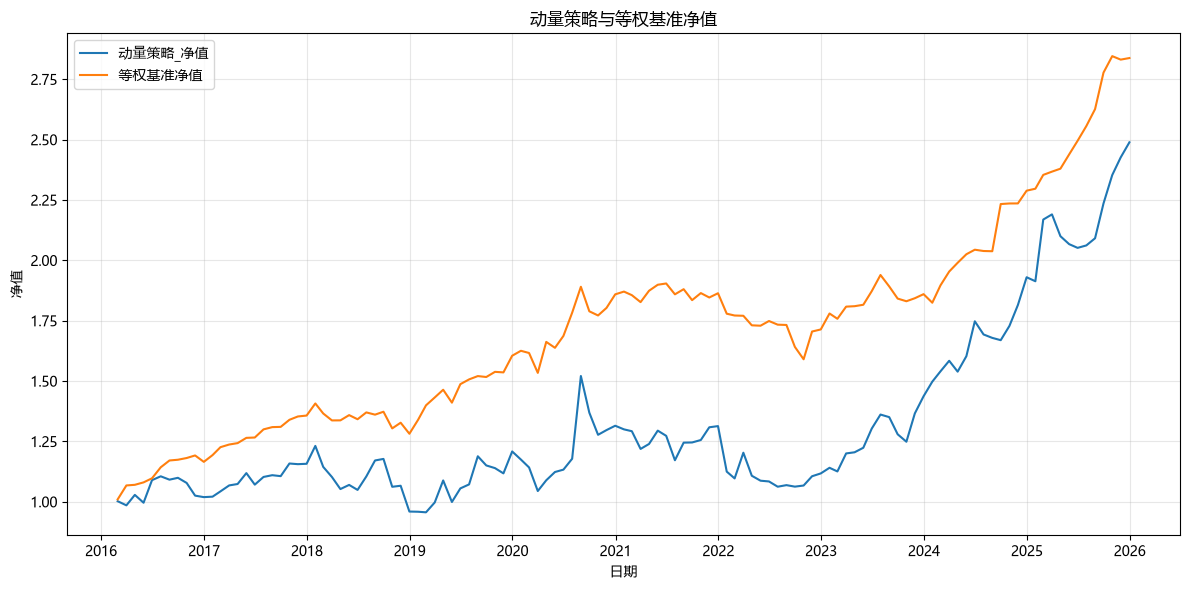

In [61]:
plt.figure(figsize=(12, 6))

for column in net_wealth.columns:
    plt.plot(
        net_wealth.index,
        net_wealth[column],
        label=column,
    )

plt.title("动量策略与等权基准净值")
plt.xlabel("日期")
plt.ylabel("净值")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

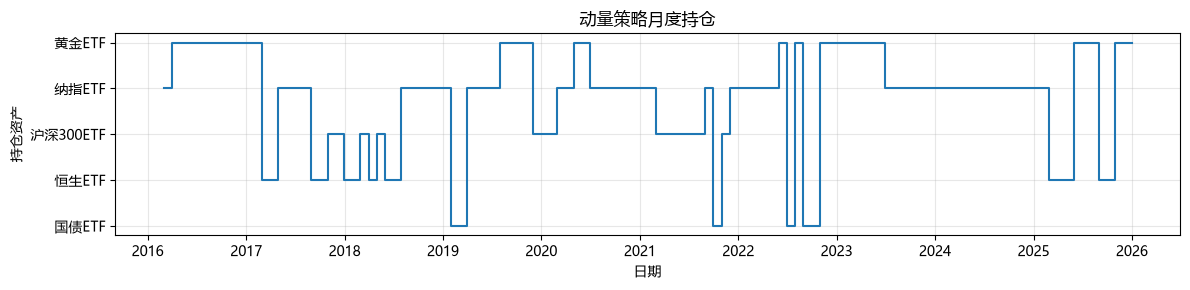

In [62]:
held_asset = held_weights.idxmax(axis=1)

plt.figure(figsize=(12, 3))

plt.step(
    held_asset.index,
    held_asset.astype("category").cat.codes,
    where="post",
)

plt.yticks(
    range(len(held_asset.astype("category").cat.categories)),
    held_asset.astype("category").cat.categories,
)

plt.title("动量策略月度持仓")
plt.xlabel("日期")
plt.ylabel("持仓资产")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 10. 样本内外表现对比

本节将历史回测区间按时间划分为样本内和样本外阶段，
比较动量策略与等权基准在不同时间区间的表现。

这里的样本外结果用于描述时间切分后的历史表现。
由于本项目在研究过程中观察过完整样本并进行了参数敏感性分析，
该结果不应被解释为完全独立、严格的事前样本外验证。
样本外结果计算完成后，不再使用其结果调整策略规则或参数。

In [63]:
split_date = "2021-12-31"

in_sample_returns = return_comparison.loc[
    :split_date,
    [
        "动量策略_净收益",
        "等权基准",
    ],
]

out_of_sample_returns = return_comparison.loc[
    "2022-01-31":,
    [
        "动量策略_净收益",
        "等权基准",
    ],
]

in_sample_performance = pd.DataFrame({
    column: calculate_backtest_performance(
        in_sample_returns[column]
    )
    for column in in_sample_returns.columns
}).T

out_of_sample_performance = pd.DataFrame({
    column: calculate_backtest_performance(
        out_of_sample_returns[column]
    )
    for column in out_of_sample_returns.columns
}).T

print("样本内绩效：")
display(
    in_sample_performance.style.format({
        "累计收益率": "{:.2%}",
        "年化收益率": "{:.2%}",
        "年化波动率": "{:.2%}",
        "夏普比率": "{:.2f}",
        "最大回撤": "{:.2%}",
    })
)

print("样本外绩效：")
display(
    out_of_sample_performance.style.format({
        "累计收益率": "{:.2%}",
        "年化收益率": "{:.2%}",
        "年化波动率": "{:.2%}",
        "夏普比率": "{:.2f}",
        "最大回撤": "{:.2%}",
    })
)

样本内绩效：


,累计收益率,年化收益率,年化波动率,夏普比率,最大回撤
动量策略_净收益,31.35%,4.72%,19.91%,0.33,-22.94%
等权基准,86.39%,11.10%,9.10%,1.21,-8.92%


样本外绩效：


,累计收益率,年化收益率,年化波动率,夏普比率,最大回撤
动量策略_净收益,89.49%,17.33%,16.59%,1.05,-11.70%
等权基准,52.26%,11.08%,9.37%,1.17,-10.61%


In [64]:
lookback_list = [3, 6, 9, 12, 18]

sensitivity_results = []

for lookback in lookback_list:
    momentum_test = (
        monthly_prices
        / monthly_prices.shift(lookback)
        - 1
    )

    valid_momentum_test = momentum_test.dropna(how="any")

    rank_test = valid_momentum_test.rank(
        axis=1,
        ascending=False,
        method="first",
    )

    weights_test = rank_test.eq(1).astype(float)
    held_weights_test = weights_test.shift(1)

    common_dates = held_weights_test.dropna(
        how="any"
    ).index.intersection(monthly_returns.index)

    held_weights_test = held_weights_test.loc[common_dates]
    returns_test = monthly_returns.loc[common_dates]

    gross_test = (
        held_weights_test * returns_test
    ).sum(axis=1)

    turnover_test = (
        held_weights_test
        - held_weights_test.shift(1).fillna(0)
    ).abs().sum(axis=1)

    net_test = (
        gross_test
        - turnover_test * transaction_cost_rate
    )

    metrics_test = calculate_backtest_performance(
        net_test
    )

    sensitivity_results.append({
        "动量窗口（月）": lookback,
        "累计收益率": metrics_test["累计收益率"],
        "年化收益率": metrics_test["年化收益率"],
        "年化波动率": metrics_test["年化波动率"],
        "夏普比率": metrics_test["夏普比率"],
        "最大回撤": metrics_test["最大回撤"],
    })

sensitivity_results = pd.DataFrame(sensitivity_results)

display(
    sensitivity_results.style.format({
        "累计收益率": "{:.2%}",
        "年化收益率": "{:.2%}",
        "年化波动率": "{:.2%}",
        "夏普比率": "{:.2f}",
        "最大回撤": "{:.2%}",
    })
)

,动量窗口（月）,累计收益率,年化收益率,年化波动率,夏普比率,最大回撤
0,3,-11.48%,-1.14%,17.82%,0.03,-49.11%
1,6,92.81%,6.51%,18.01%,0.44,-20.30%
2,9,34.92%,2.99%,18.04%,0.25,-32.06%
3,12,148.90%,9.63%,18.63%,0.58,-30.14%
4,18,270.59%,14.92%,17.73%,0.87,-30.70%


## 11. 保存分析结果

将策略绩效、月度收益、净值、换手率、参数敏感性和图表保存到 `outputs/`，
便于复现、查看和上传 GitHub。

In [65]:
output_dir = Path("outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# 保存绩效表
performance.to_csv(
    output_dir / "performance.csv",
    encoding="utf-8-sig",
)

# 保存月度收益、换手率和交易成本
return_comparison.to_csv(
    output_dir / "monthly_returns_and_turnover.csv",
    encoding="utf-8-sig",
)

# 保存策略净值比较
wealth_comparison.to_csv(
    output_dir / "wealth_comparison.csv",
    encoding="utf-8-sig",
)

# 保存持仓记录
held_weights.to_csv(
    output_dir / "held_weights.csv",
    encoding="utf-8-sig",
)

# 保存参数敏感性结果
sensitivity_results.to_csv(
    output_dir / "sensitivity_results.csv",
    index=False,
    encoding="utf-8-sig",
)

print("表格结果已保存到：", output_dir.resolve())

表格结果已保存到： C:\Users\10529\Documents\quant-projects\etf-momentum-backtest\outputs


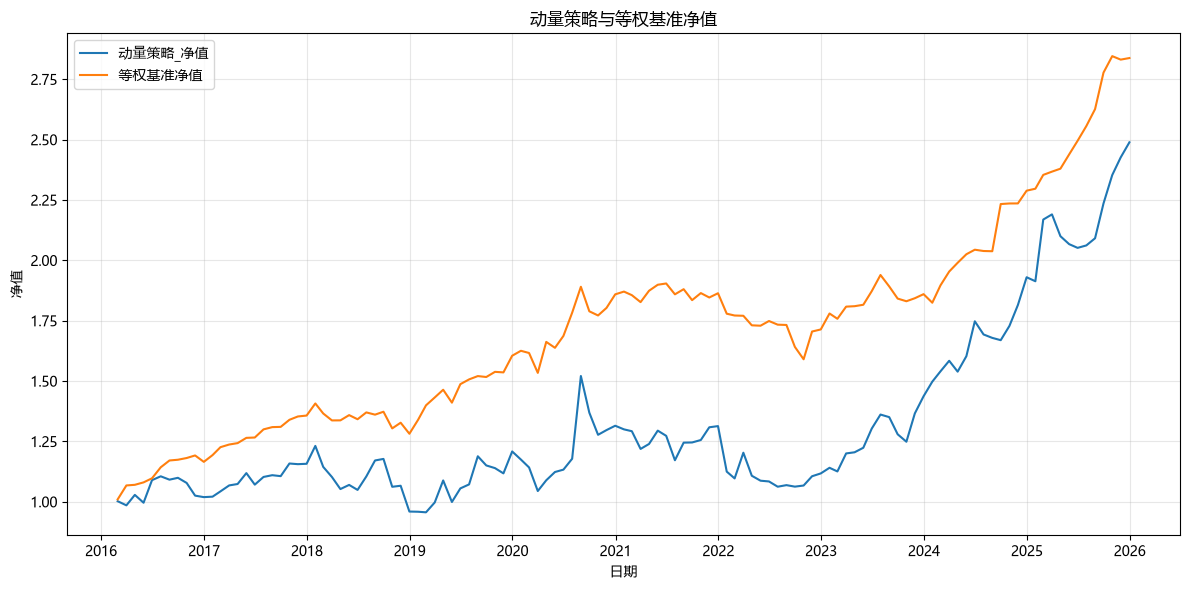

In [66]:
fig, ax = plt.subplots(figsize=(12, 6))

for column in net_wealth.columns:
    ax.plot(
        net_wealth.index,
        net_wealth[column],
        label=column,
    )

ax.set_title("动量策略与等权基准净值")
ax.set_xlabel("日期")
ax.set_ylabel("净值")
ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(
    output_dir / "wealth_comparison.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

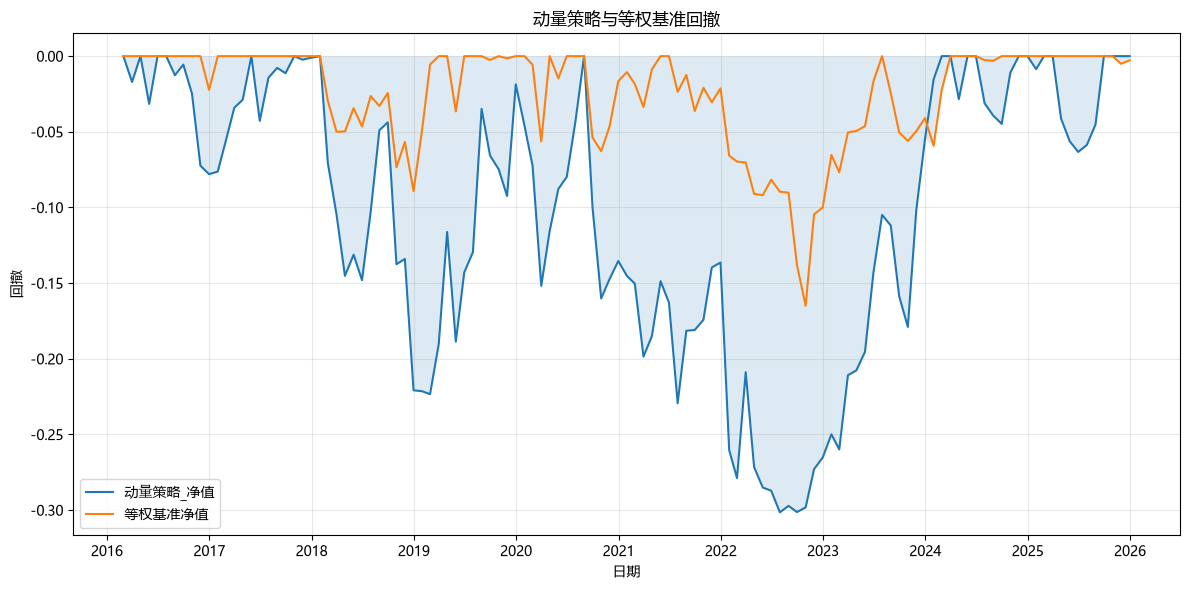

In [67]:
drawdown = net_wealth.div(
    net_wealth.cummax()
).sub(1)

drawdown.to_csv(
    output_dir / "drawdown.csv",
    encoding="utf-8-sig",
)

fig, ax = plt.subplots(figsize=(12, 6))

for column in drawdown.columns:
    ax.plot(
        drawdown.index,
        drawdown[column],
        label=column,
    )

ax.fill_between(
    drawdown.index,
    drawdown.min(axis=1),
    0,
    alpha=0.15,
)

ax.set_title("动量策略与等权基准回撤")
ax.set_xlabel("日期")
ax.set_ylabel("回撤")
ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(
    output_dir / "drawdown_comparison.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

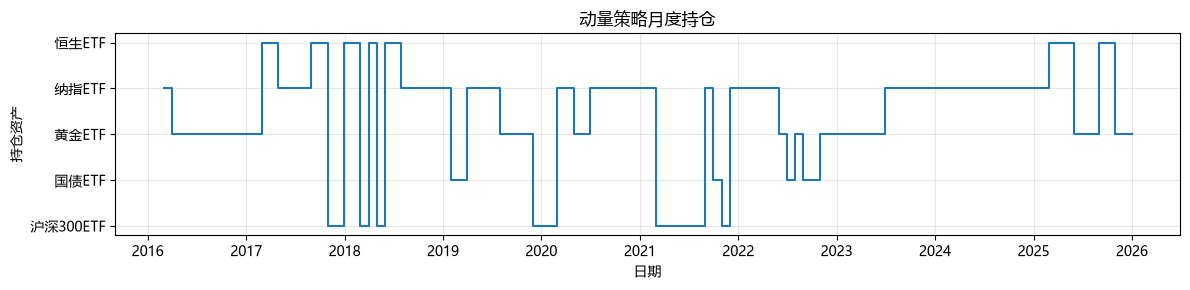

In [68]:
held_asset = held_weights.idxmax(axis=1)

asset_categories = pd.Categorical(
    held_asset,
    categories=held_weights.columns,
    ordered=True,
)

asset_codes = asset_categories.codes

fig, ax = plt.subplots(figsize=(12, 3))

ax.step(
    held_asset.index,
    asset_codes,
    where="post",
)

ax.set_yticks(range(len(held_weights.columns)))
ax.set_yticklabels(held_weights.columns)

ax.set_title("动量策略月度持仓")
ax.set_xlabel("日期")
ax.set_ylabel("持仓资产")
ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(
    output_dir / "monthly_holdings.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

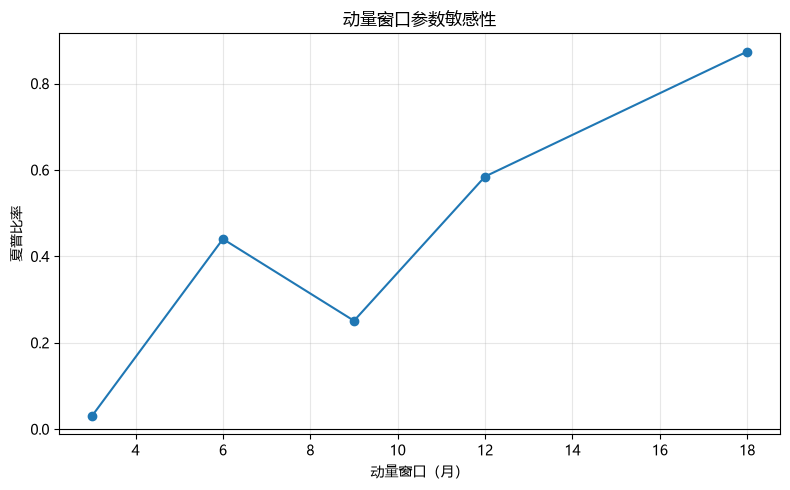

In [69]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    sensitivity_results["动量窗口（月）"],
    sensitivity_results["夏普比率"],
    marker="o",
)

ax.axhline(
    0,
    color="black",
    linewidth=0.8,
)

ax.set_title("动量窗口参数敏感性")
ax.set_xlabel("动量窗口（月）")
ax.set_ylabel("夏普比率")
ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(
    output_dir / "lookback_sensitivity.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

In [70]:
print("输出文件：")

for file_path in sorted(output_dir.iterdir()):
    print(file_path.name)

输出文件：
drawdown.csv
drawdown_comparison.png
held_weights.csv
lookback_sensitivity.png
monthly_holdings.png
monthly_returns_and_turnover.csv
performance.csv
sensitivity_results.csv
wealth_comparison.csv
wealth_comparison.png
